# Module import

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

plt.rcParams["figure.dpi"] = 300

# Load parquet

In [15]:
BASE = Path("/work/scratch-nopw2/mendrika/ASNIE/updated/parquet")

df_core_90 = pd.read_parquet(BASE / "core_thr_223p5.parquet")
df_core_95 = pd.read_parquet(BASE / "core_thr_260p1.parquet")

df_roa_90 = pd.read_parquet(BASE / "roa_thr_1p6357.parquet")
df_roa_95 = pd.read_parquet(BASE / "roa_thr_2p9205.parquet")

print(len(df_core_90), len(df_roa_90))
print(len(df_core_95), len(df_roa_95))

66379 1382781
37616 802206


# Compute distance

In [19]:
time_cols = ["year", "month", "day", "hour"]

In [20]:
def _to_cartesian_deg(lat_deg, lon_deg):
    lat = np.deg2rad(lat_deg)
    lon = np.deg2rad(lon_deg)
    x = np.cos(lat) * np.cos(lon)
    y = np.cos(lat) * np.sin(lon)
    z = np.sin(lat)
    return np.column_stack((x, y, z))

def nearest_distances_by_time(df_a, df_b, time_cols=None):

    if time_cols is None:
        time_cols = ["year", "month", "day", "hour"]

    dist_all = []
    idx_all = []

    group_b = dict(tuple(df_b.groupby(time_cols, sort=False)))

    for key, a in df_a.groupby(time_cols, sort=False):

        b = group_b.get(key, None)
        if b is None or len(a) == 0 or len(b) == 0:
            continue

        xyz_b = _to_cartesian_deg(b["lat_centroid"].values, b["lon_centroid"].values)
        tree = cKDTree(xyz_b)

        xyz_a = _to_cartesian_deg(a["lat_centroid"].values, a["lon_centroid"].values)
        chord, idx = tree.query(xyz_a, k=1)

        ang = 2.0 * np.arcsin(np.clip(chord / 2.0, 0.0, 1.0))
        dist_km = 6371.0 * ang

        dist_all.append(dist_km)
        idx_all.append(b.index.values[idx])

    if len(dist_all) == 0:
        return np.array([]), np.array([], dtype=int)

    return np.concatenate(dist_all), np.concatenate(idx_all)

In [21]:
core_roa_90_dist, core_roa_90_idx = nearest_distances_by_time(df_core_90, df_roa_90)
roa_core_90_dist, roa_core_90_idx = nearest_distances_by_time(df_roa_90, df_core_90)

core_roa_95_dist, core_roa_95_idx = nearest_distances_by_time(df_core_95, df_roa_95)
roa_core_95_dist, roa_core_95_idx = nearest_distances_by_time(df_roa_95, df_core_95)

In [23]:
def summary_stats(dist):
    return {
        "median_km": float(np.median(dist)),
        "match_50km": float(np.mean(dist <= 50)),
        "match_100km": float(np.mean(dist <= 100))
    }

print("Core → RoA 90:", summary_stats(core_roa_90_dist))
print("Core → RoA 95:", summary_stats(core_roa_95_dist))

print("RoA → Core 90:", summary_stats(roa_core_90_dist))
print("RoA → Core 95:", summary_stats(roa_core_95_dist))

Core → RoA 90: {'median_km': 29.19970703994088, 'match_50km': 0.6797330481025625, 'match_100km': 0.9139336235857726}
Core → RoA 95: {'median_km': 18.076941850661015, 'match_50km': 0.824356656741812, 'match_100km': 0.961665248830285}
RoA → Core 90: {'median_km': 442.5740185036502, 'match_50km': 0.04623436393760111, 'match_100km': 0.10326002454473991}
RoA → Core 95: {'median_km': 441.5570832971091, 'match_50km': 0.05921795648499263, 'match_100km': 0.11926612366399653}


# Matching rate curve

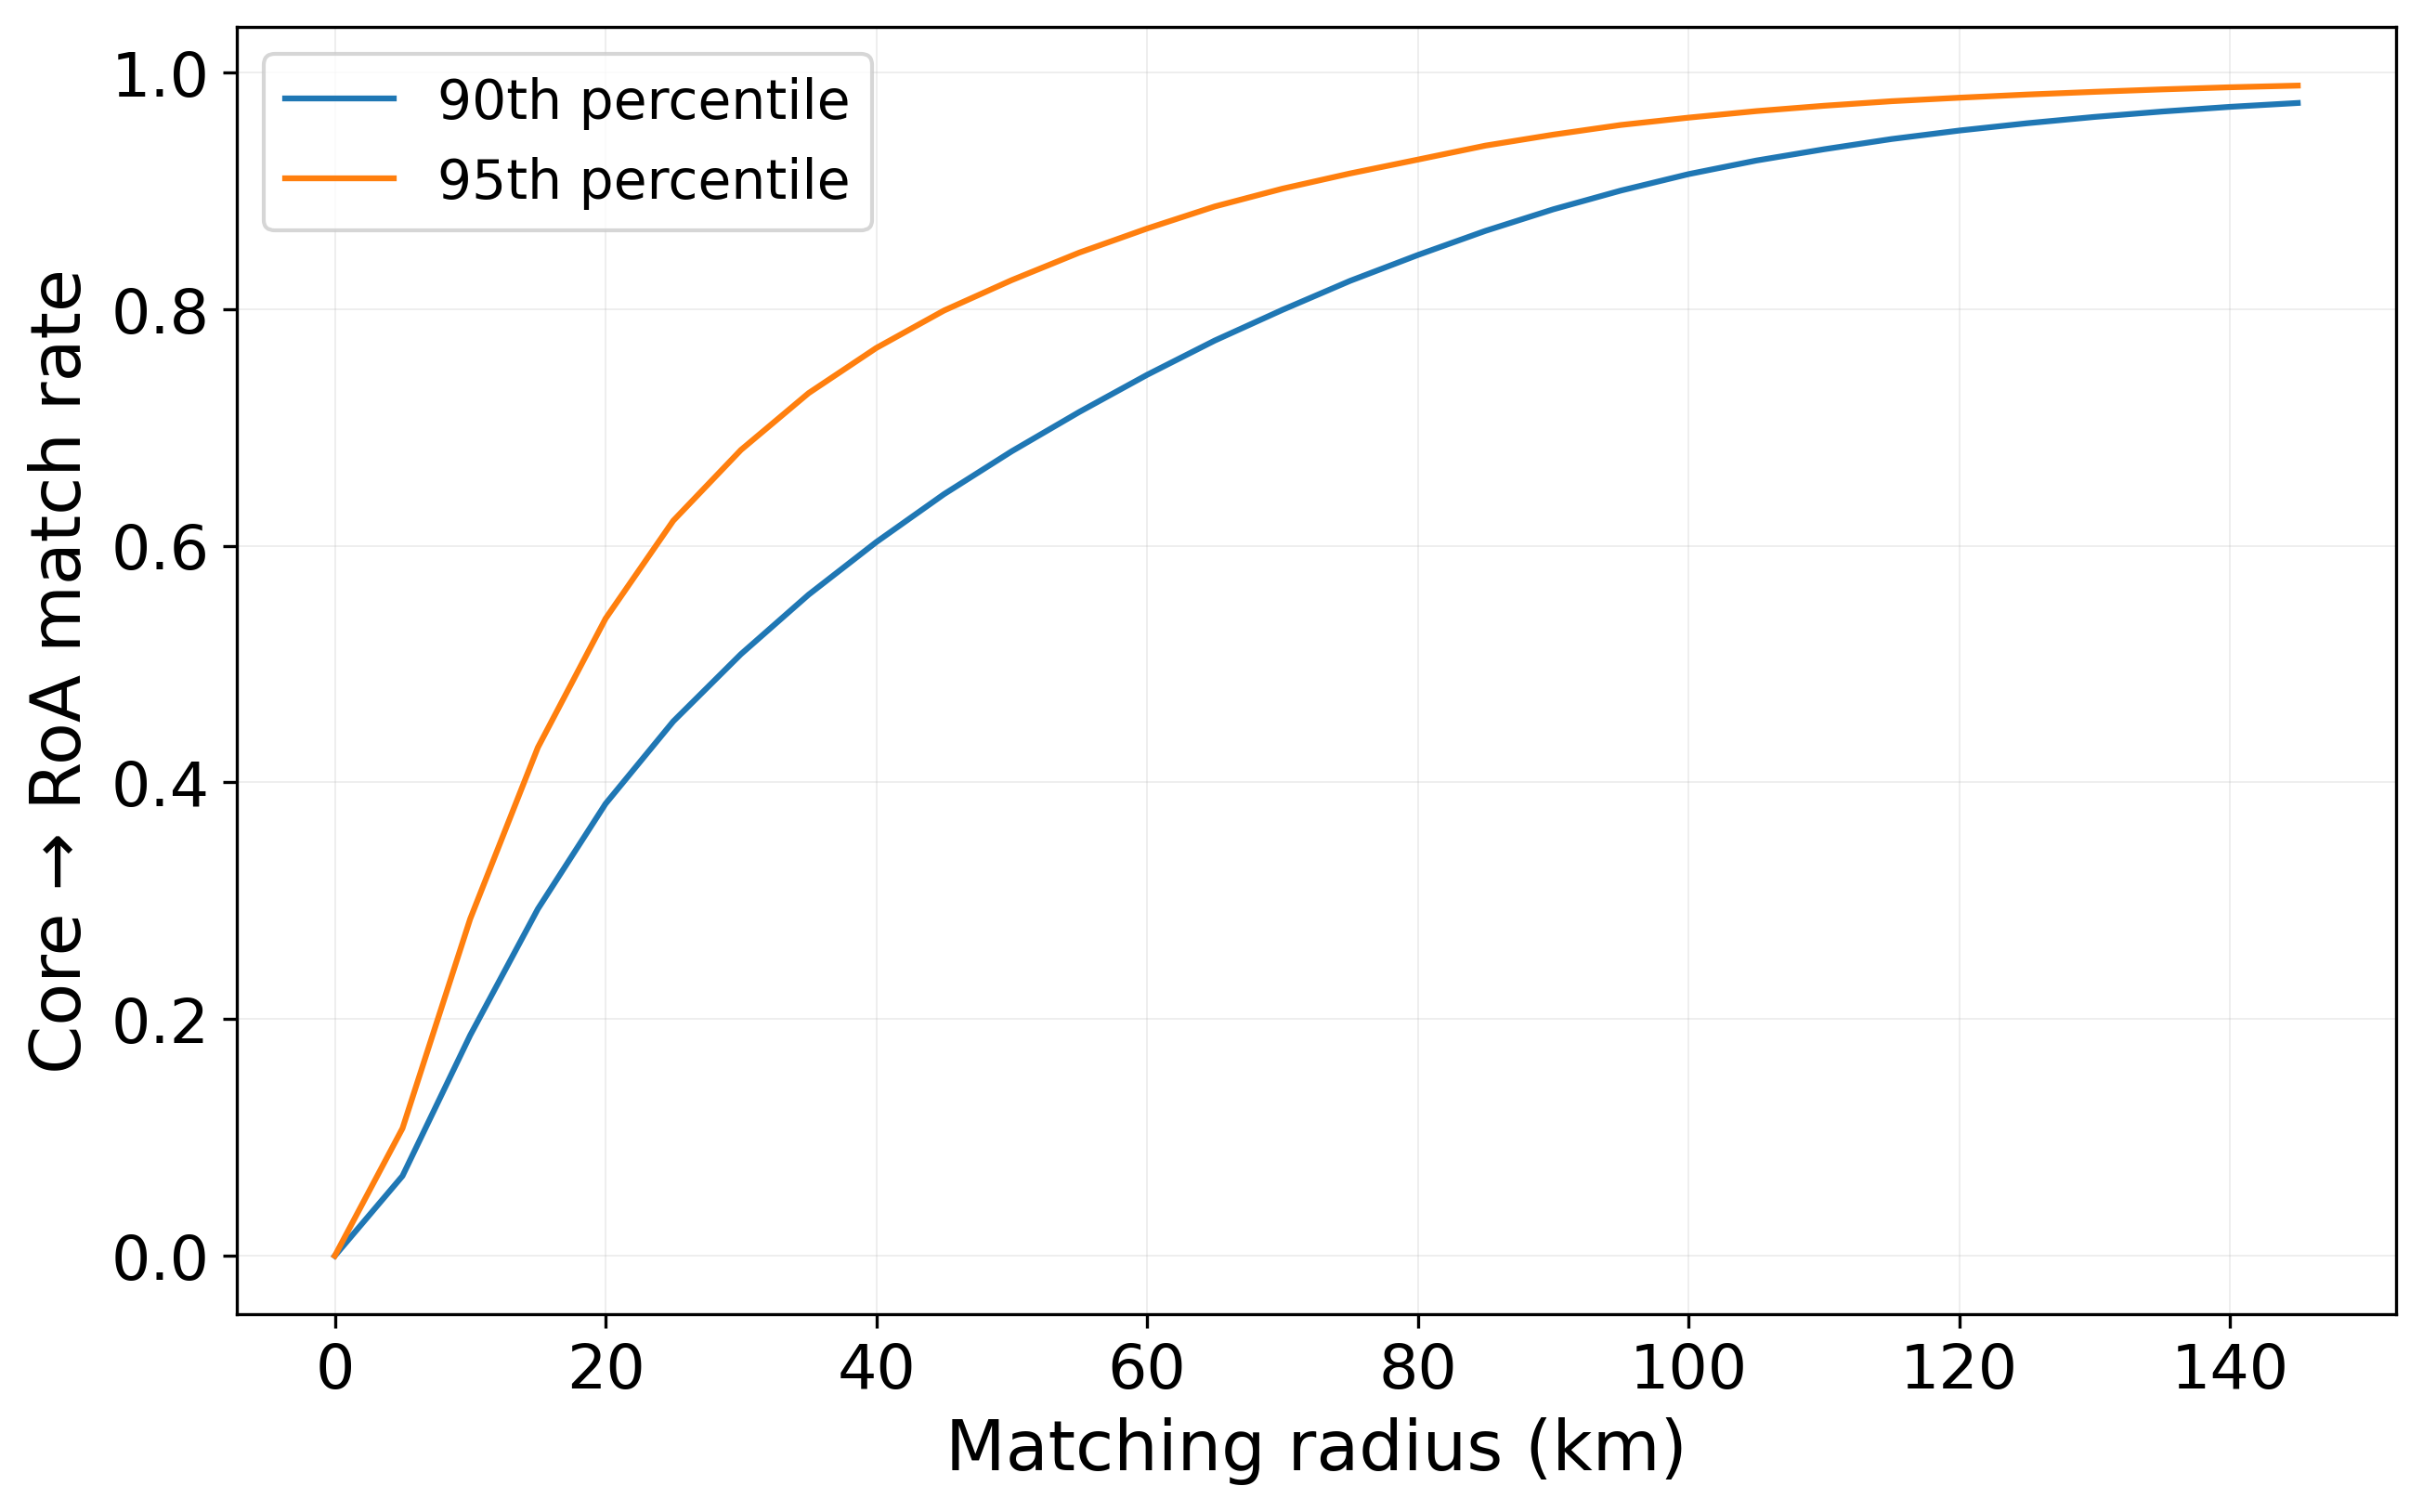

In [30]:
radii = np.arange(0, 150, 5)

rates_90 = [np.mean(core_roa_90_dist <= r) for r in radii]
rates_95 = [np.mean(core_roa_95_dist <= r) for r in radii]

plt.figure(figsize=(10, 6), dpi=300)

plt.plot(radii, rates_90, label="90th percentile")
plt.plot(radii, rates_95, label="95th percentile")

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Core → RoA match rate", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()

# Conditional probability vs core size

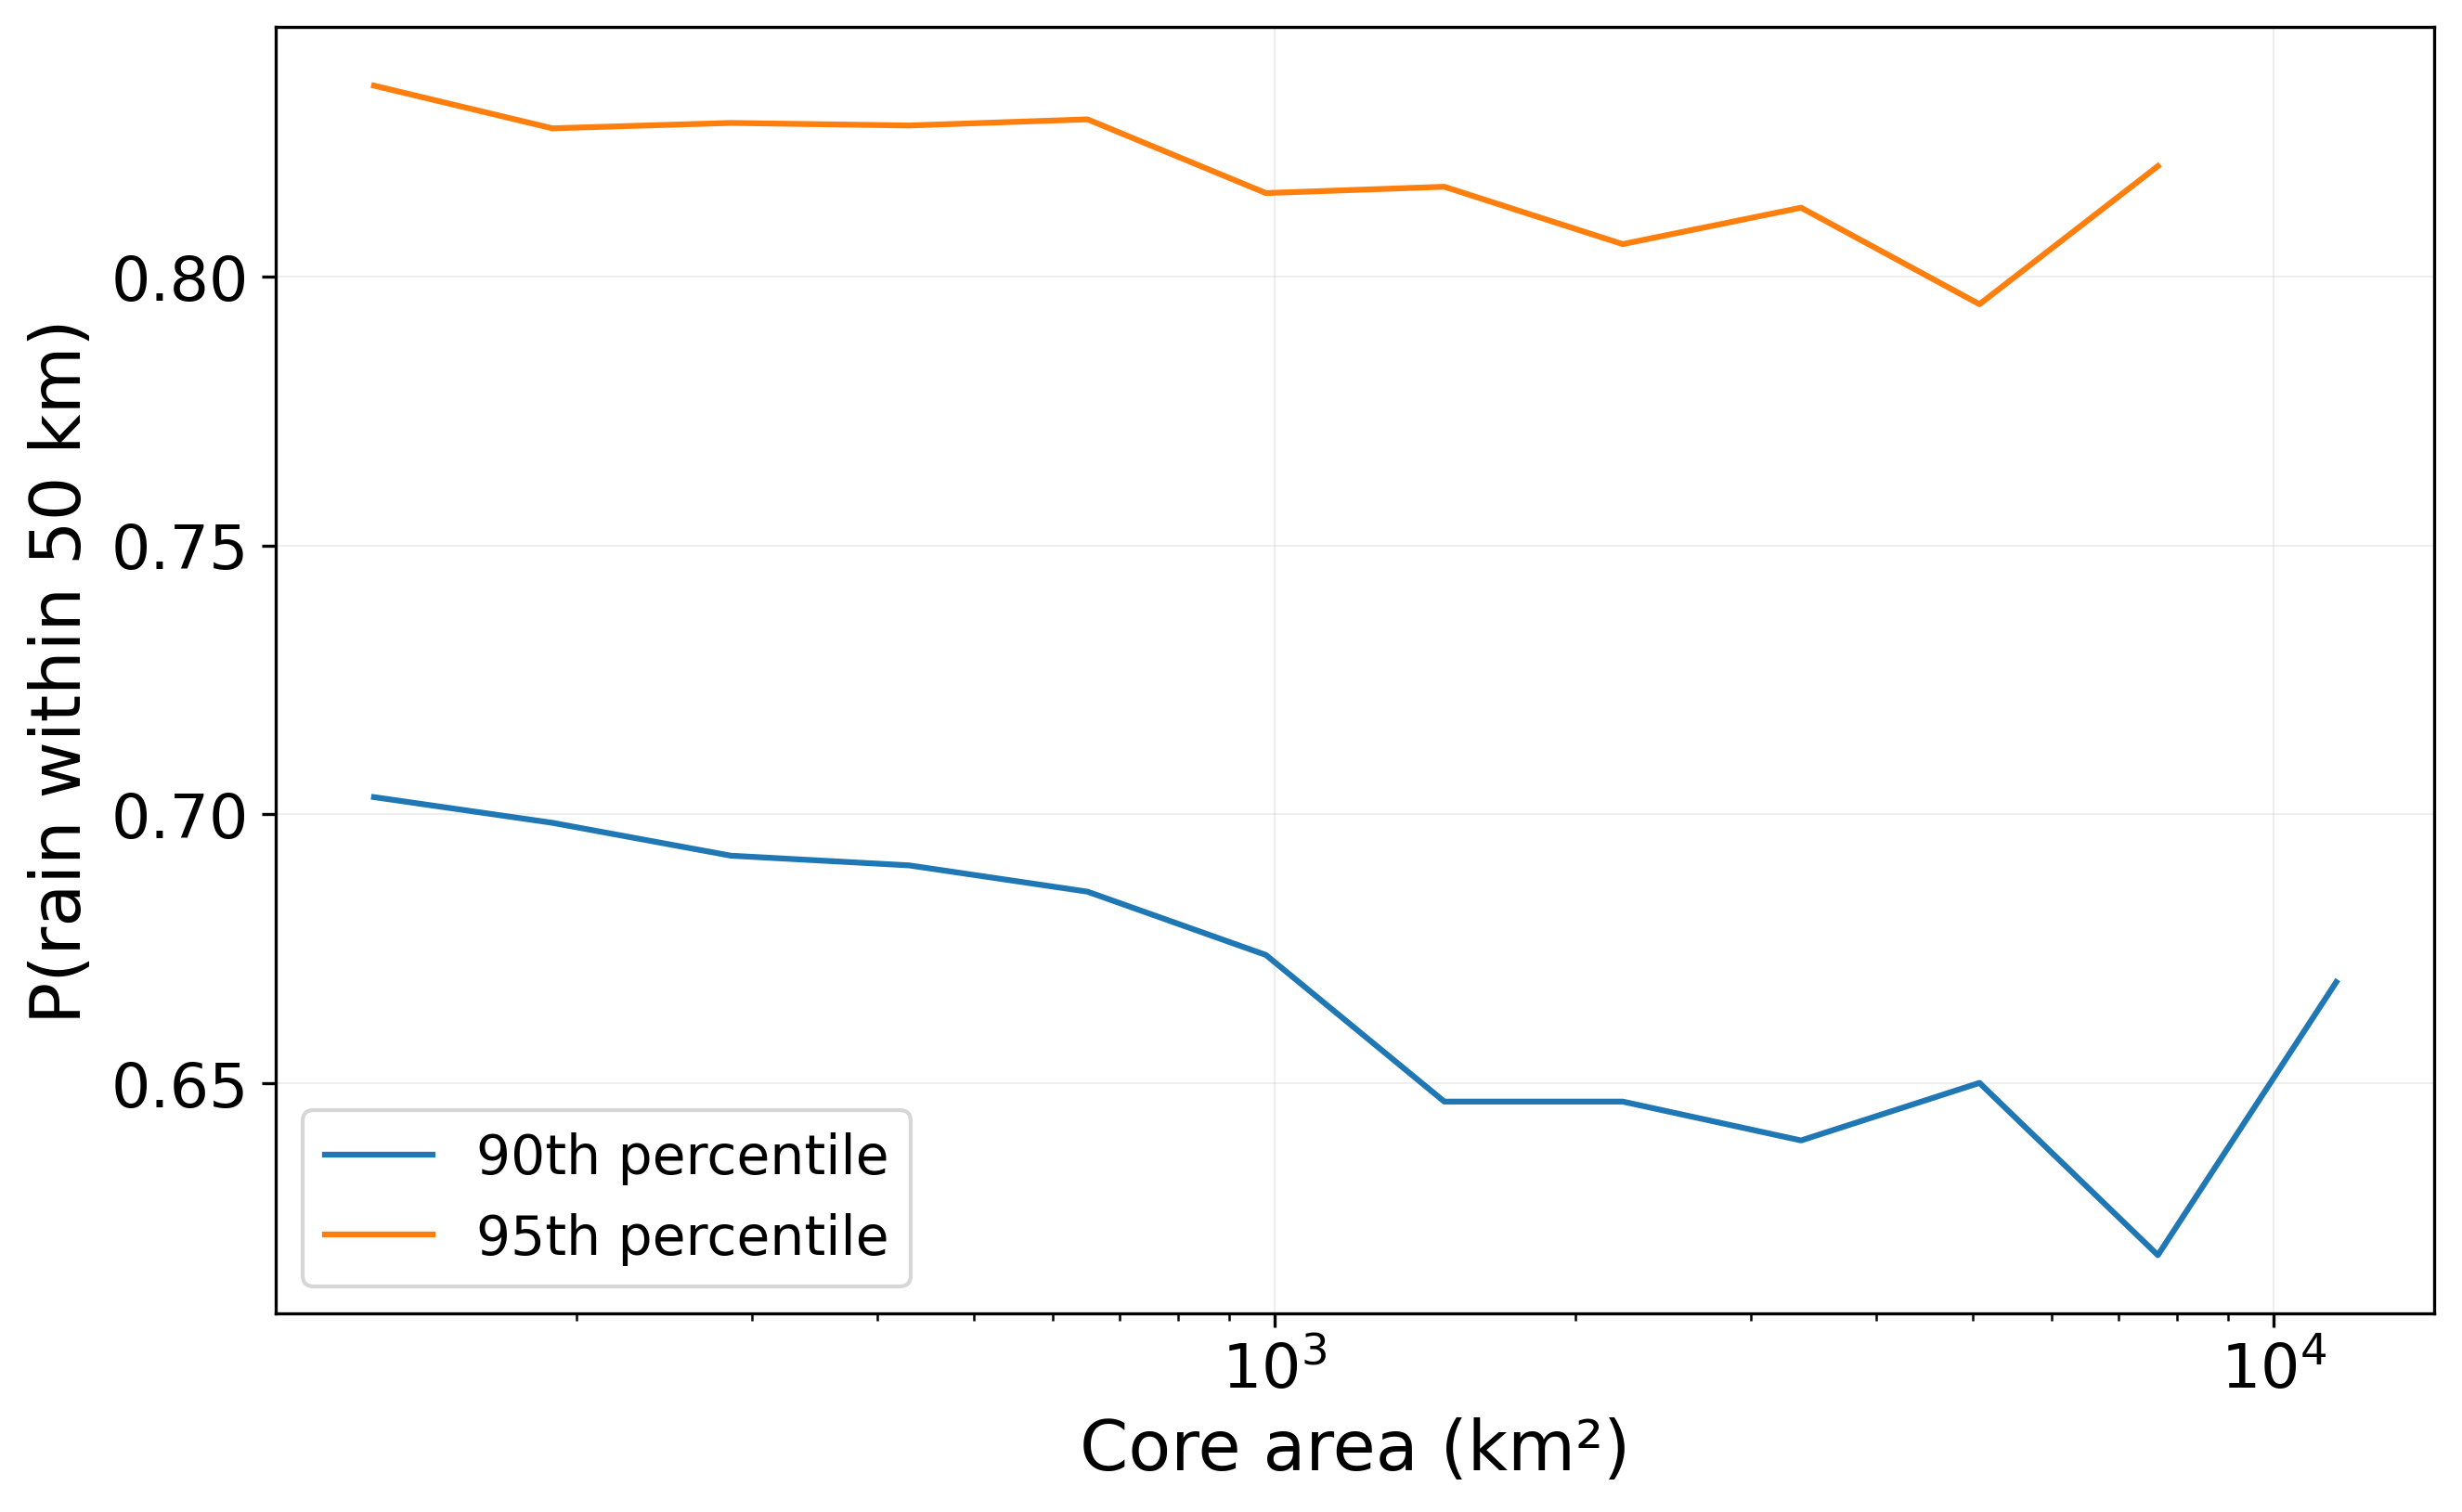

In [28]:
# Attach distances to core dataframes
df_temp_90 = df_core_90.iloc[:len(core_roa_90_dist)].copy()
df_temp_90["dist"] = core_roa_90_dist

df_temp_95 = df_core_95.iloc[:len(core_roa_95_dist)].copy()
df_temp_95["dist"] = core_roa_95_dist

# Define log-spaced size bins (km²)
bins = np.logspace(2, 4.5, 15)

df_temp_90["size_bin"] = pd.cut(df_temp_90["size"], bins)
df_temp_95["size_bin"] = pd.cut(df_temp_95["size"], bins)

# Compute conditional probabilities
prob_50_90 = (
    df_temp_90
    .groupby("size_bin", observed=True)["dist"]
    .apply(lambda x: np.mean(x <= 50))
)

counts_90 = (
    df_temp_90
    .groupby("size_bin", observed=True)["dist"]
    .count()
)

prob_50_95 = (
    df_temp_95
    .groupby("size_bin", observed=True)["dist"]
    .apply(lambda x: np.mean(x <= 50))
)

counts_95 = (
    df_temp_95
    .groupby("size_bin", observed=True)["dist"]
    .count()
)

# Remove bins with too few samples
min_count = 100

valid_bins_90 = counts_90[counts_90 >= min_count].index
valid_bins_95 = counts_95[counts_95 >= min_count].index

prob_50_90_clean = prob_50_90[valid_bins_90]
prob_50_95_clean = prob_50_95[valid_bins_95]

bin_centres_90 = [b.mid for b in prob_50_90_clean.index]
bin_centres_95 = [b.mid for b in prob_50_95_clean.index]

# Plot overlay
plt.figure(figsize=(10, 6), dpi=300)

plt.plot(bin_centres_90, prob_50_90_clean, label="90th percentile")
plt.plot(bin_centres_95, prob_50_95_clean, label="95th percentile")

plt.xscale("log")

plt.xlabel("Core area (km²)", fontsize=18)
plt.ylabel("P(rain within 50 km)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()

# Intensity linkage

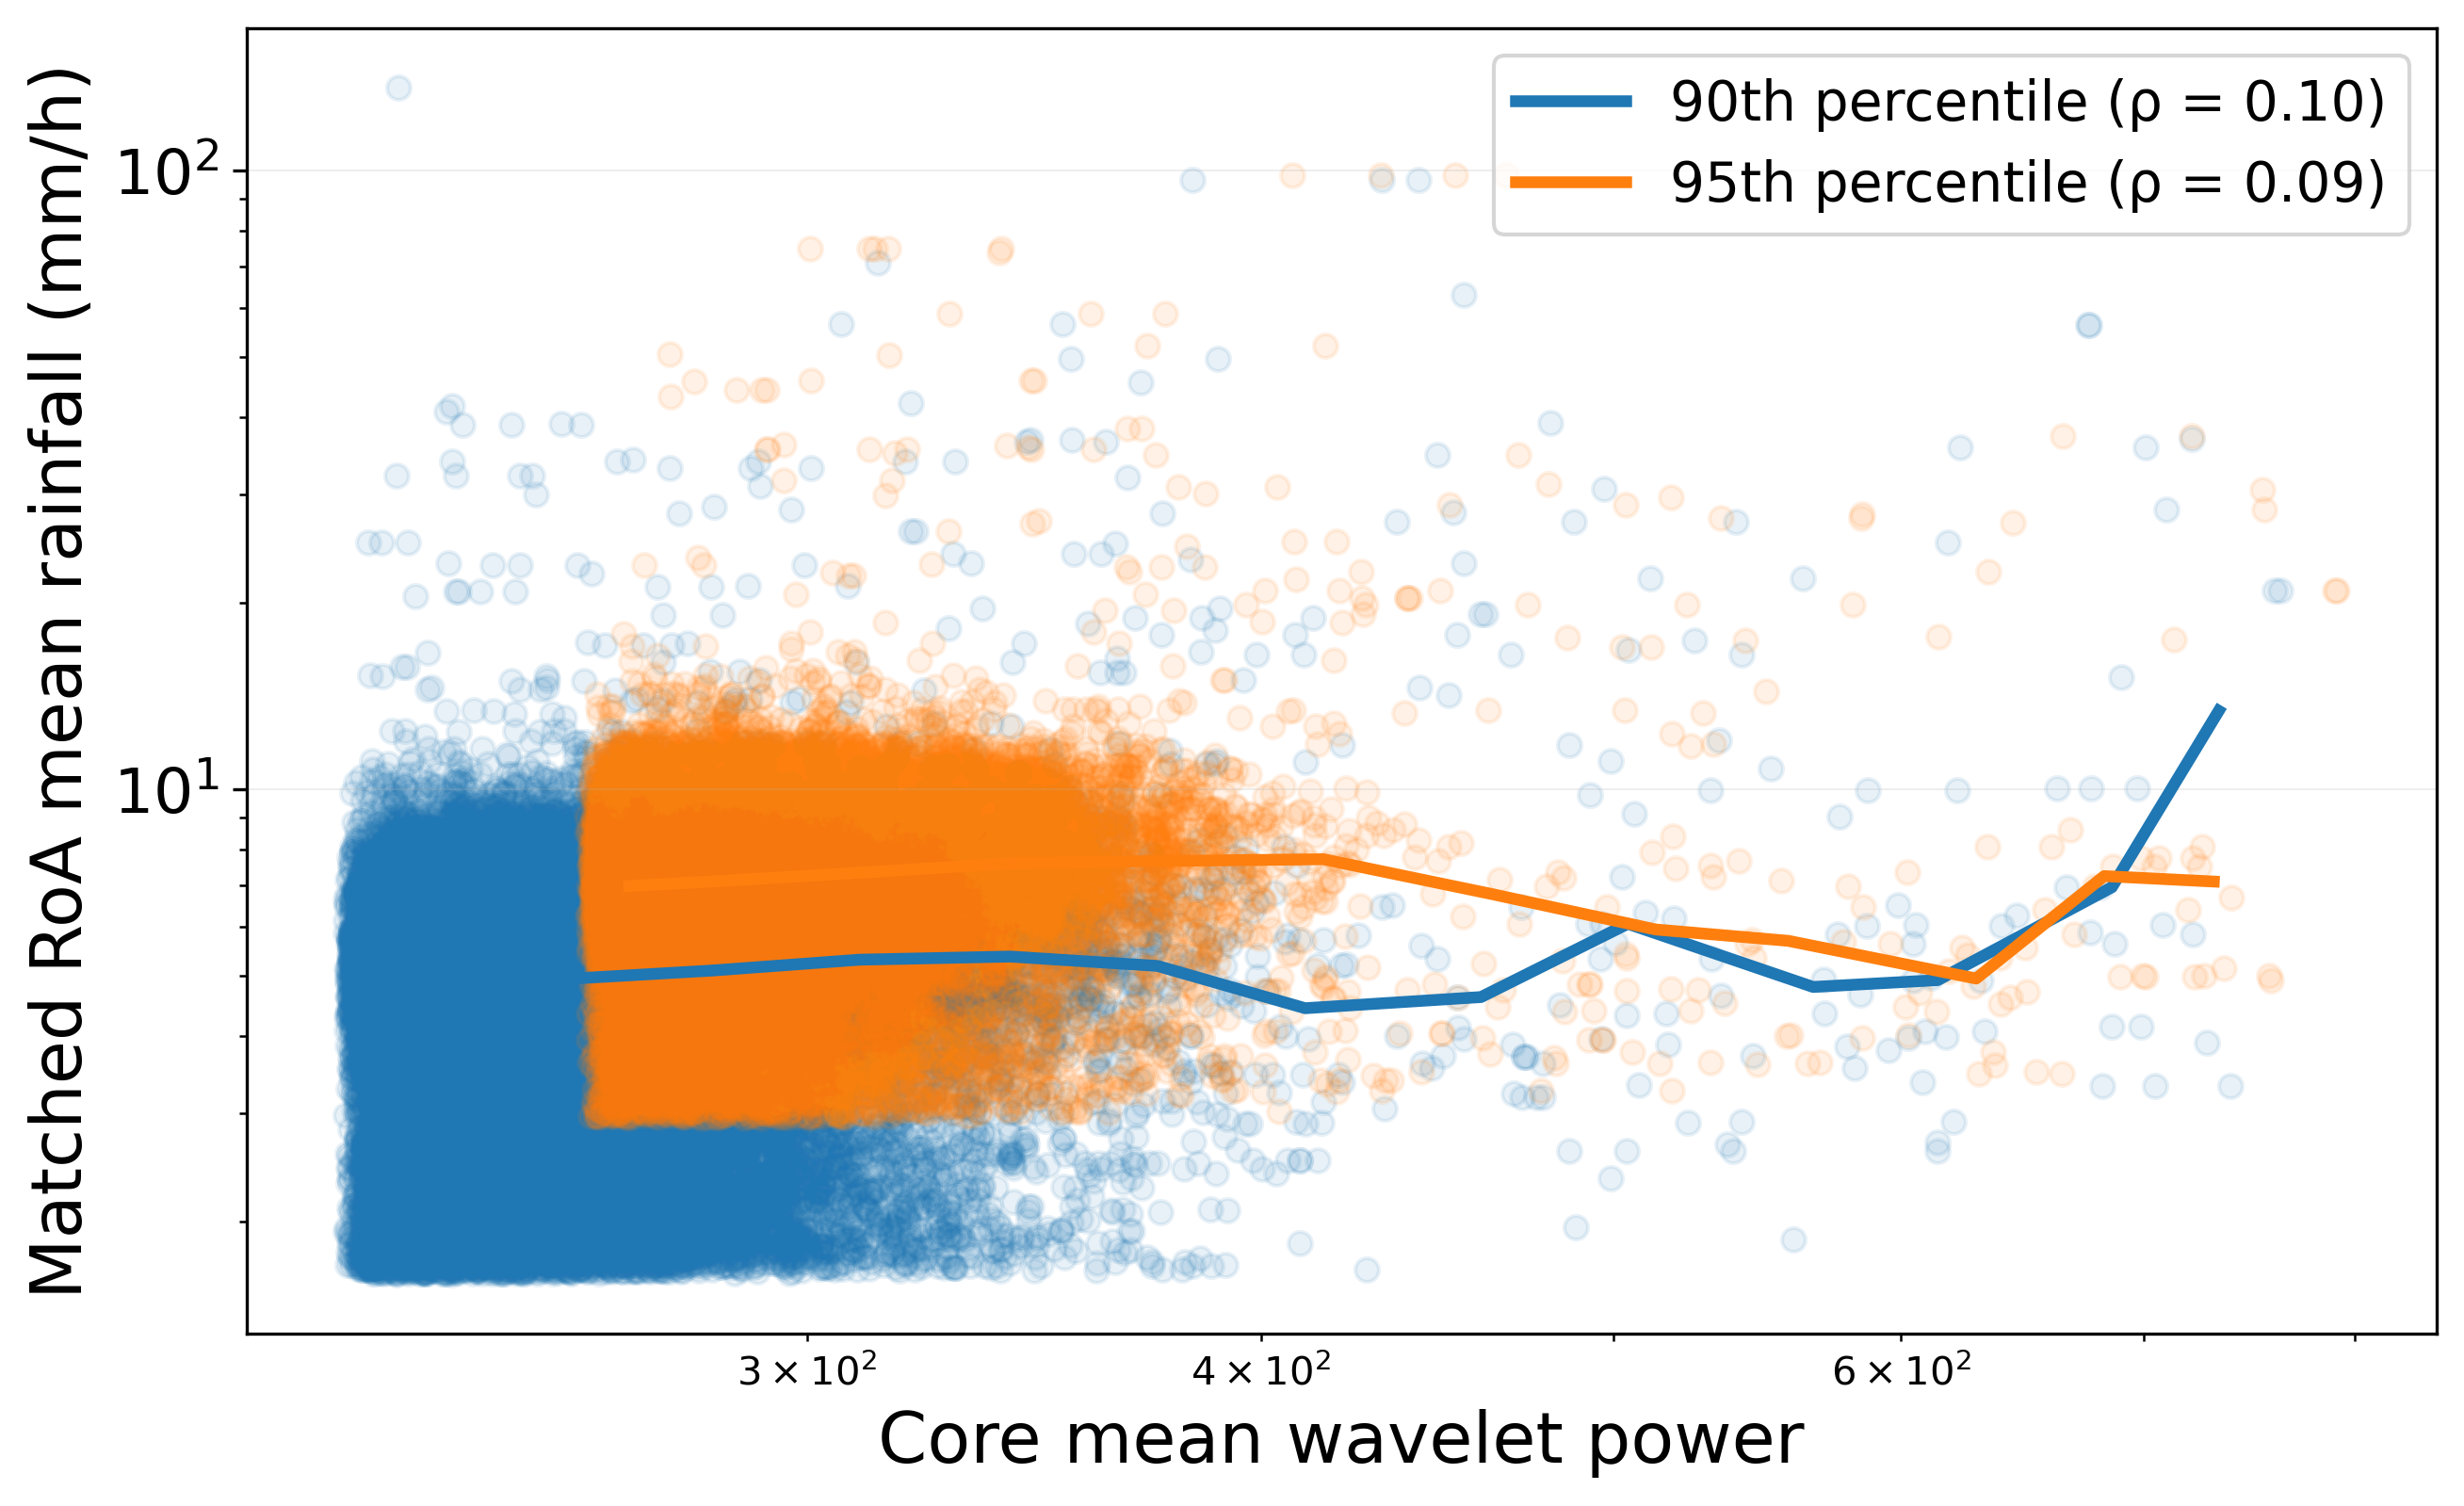

In [41]:
from matplotlib.lines import Line2D

plt.figure(figsize=(10, 6), dpi=300)

# Scatter (no legend from these)
plt.scatter(core_wp_90, matched_rain_90,
            alpha=0.1)

plt.scatter(core_wp_95, matched_rain_95,
            alpha=0.1)

# Median lines
plt.plot(centres_90, median_90, linewidth=3)
plt.plot(centres_95, median_95, linewidth=3)

plt.yscale("log")
plt.xscale("log")

# Custom legend handles (clean and sharp)
legend_elements = [
    Line2D([0], [0], color="C0", lw=3,
           label=f"90th percentile (ρ = {rho_90:.2f})"),
    Line2D([0], [0], color="C1", lw=3,
           label=f"95th percentile (ρ = {rho_95:.2f})")
]

plt.legend(handles=legend_elements, fontsize=14)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Core mean wavelet power", fontsize=18)
plt.ylabel("Matched RoA mean rainfall (mm/h)", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()

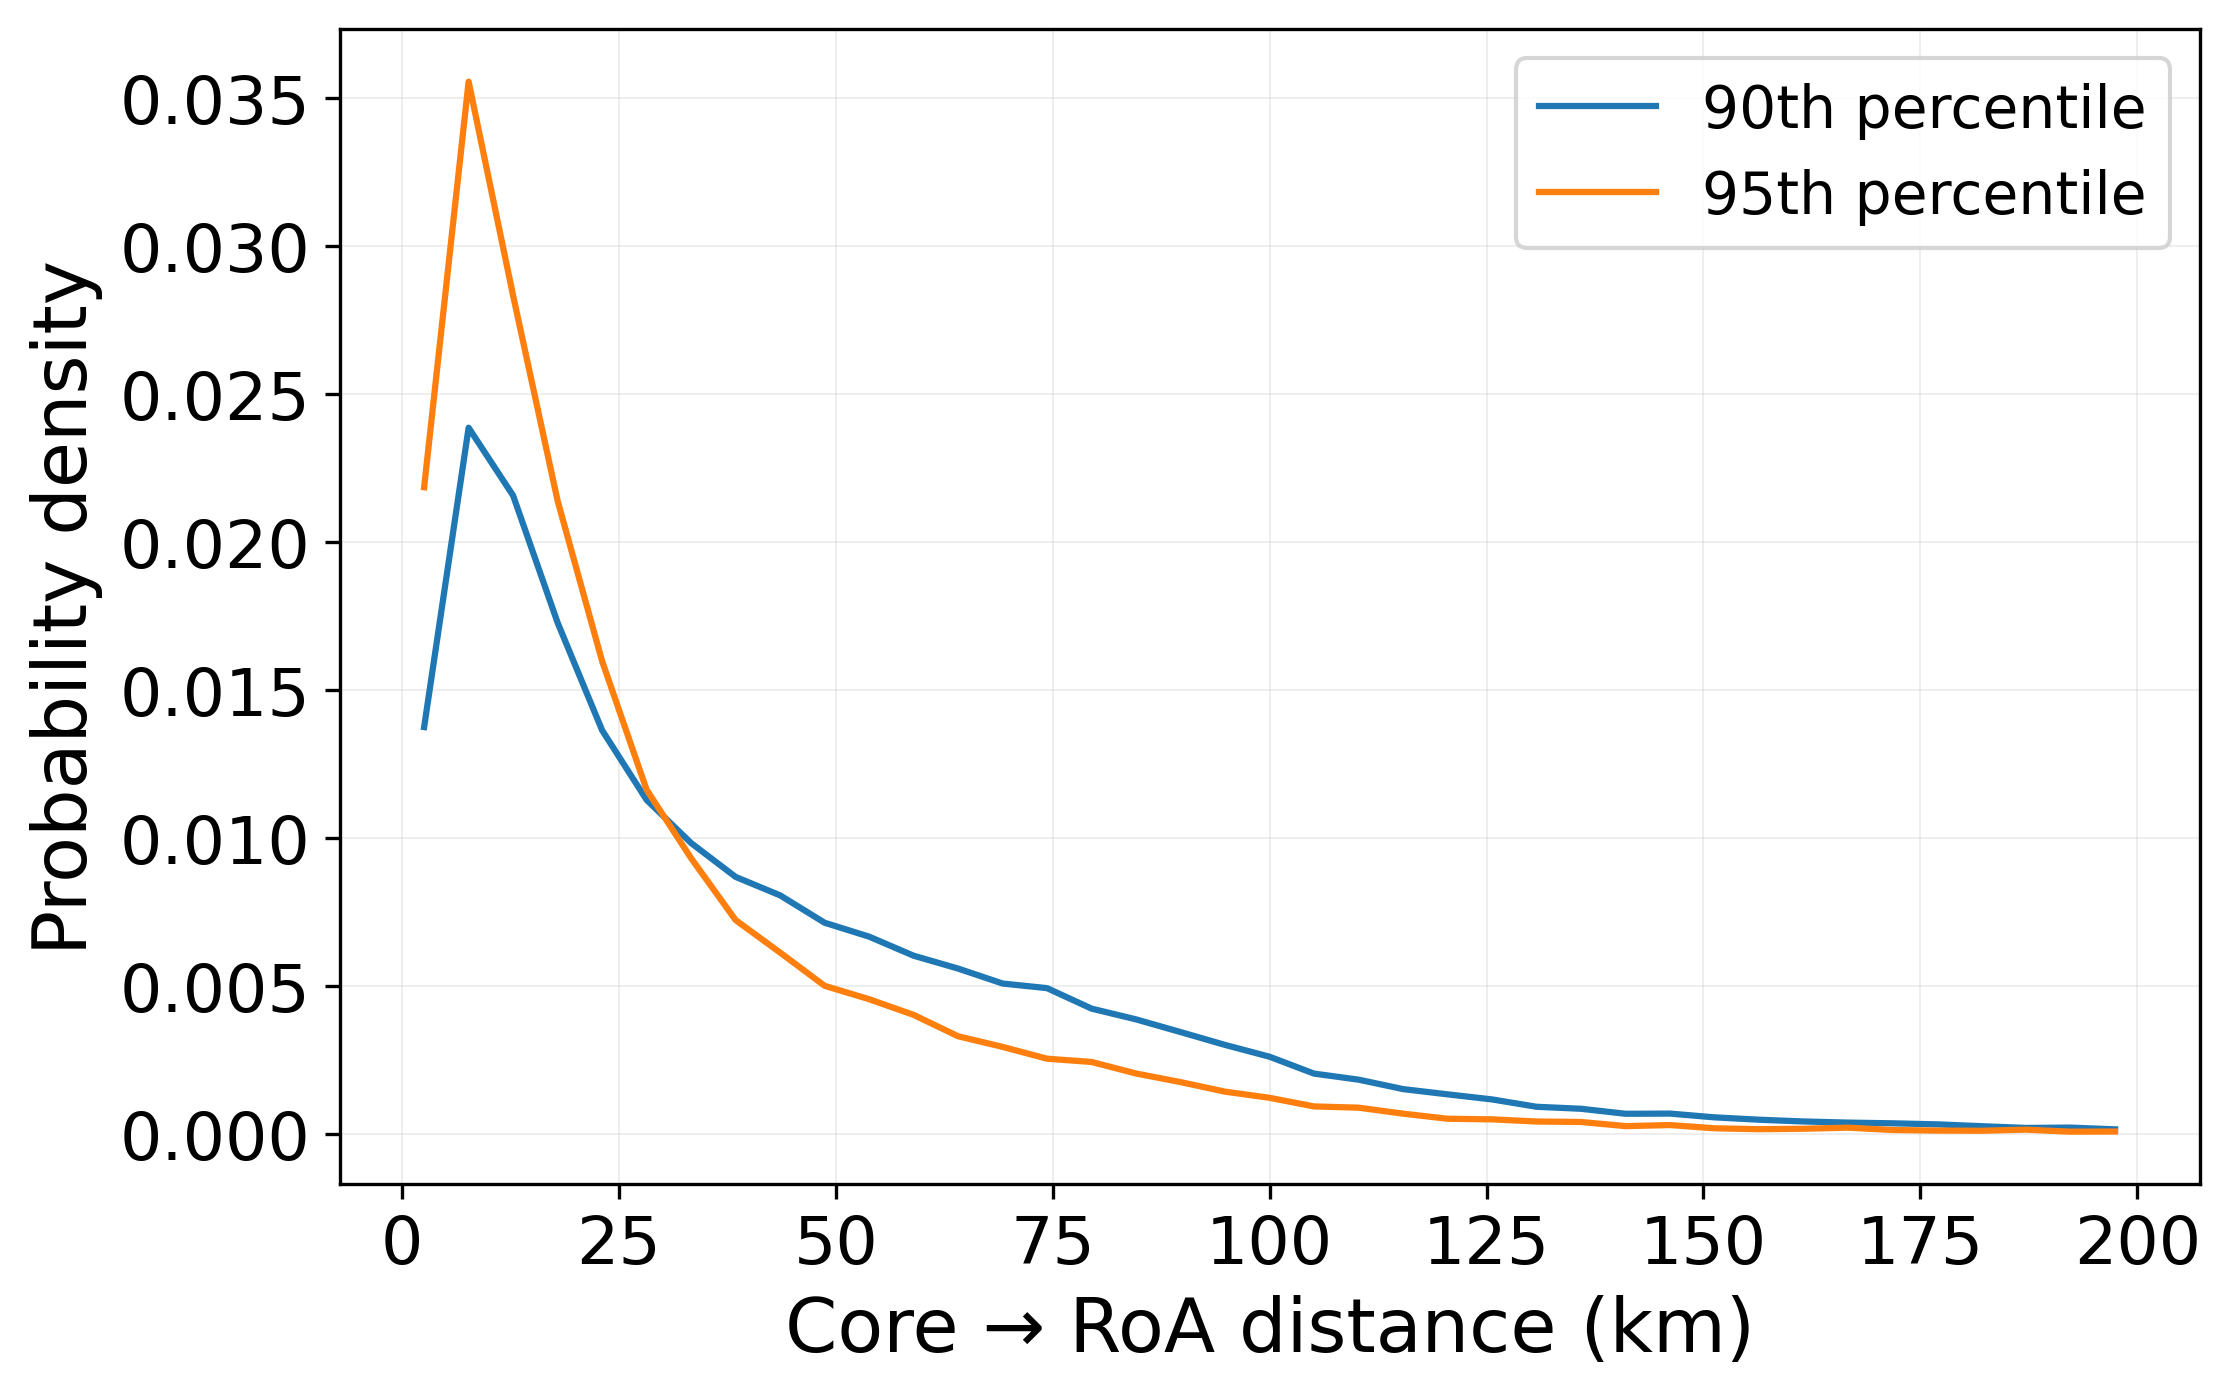

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Distance arrays already computed
# core_roa_90_dist
# core_roa_95_dist

# Remove extreme outliers if needed (optional but recommended)
max_plot_radius = 200  # km
dist_90 = core_roa_90_dist[core_roa_90_dist <= max_plot_radius]
dist_95 = core_roa_95_dist[core_roa_95_dist <= max_plot_radius]

# Define bins
bins = np.linspace(0, max_plot_radius, 40)

# Compute histogram densities
hist_90, bin_edges = np.histogram(dist_90, bins=bins, density=True)
hist_95, _ = np.histogram(dist_95, bins=bins, density=True)

bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(8, 5))

plt.plot(bin_centres, hist_90, label="90th percentile")
plt.plot(bin_centres, hist_95, label="95th percentile")

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Core → RoA distance (km)", fontsize=18)
plt.ylabel("Probability density", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()